# Generative Adversarial Networks 📚 ❓
## How does this learn to create new data?

# More detailed GANs ⁉️
## How is the Generator Trained?

# What are the uses of GANs ❓

# Load and Check Data 🗸

# Train - Test Split

# Normalization ⁉️
## Why do we want to normalize the pictures?

# Reshape ❓
## Why do we need to reshape the pictures?

# Implementing with Keras ❔
## Import Model Library
## Create Generator
## Generator Output
## Generator Compile
## Generator Summmary
## Create Discriminator
## Discriminator Output
## Discriminator Compile
## Discriminator Summmary
## Create GANs
## GANs Summmary
## Epochs and Batch Size ❓
## Fit the Model

# Result

# CONCLUSION

In [83]:
import   numpy as  np
import  pandas as  pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load  the  data

In [84]:
train_data = pd.read_csv("/content/train.csv")
test_data = pd.read_csv("/content/test.csv")

In [85]:
print("Train Shape --> ",train_data.shape)
print("Test Shape --> ",test_data.shape)

Train Shape -->  (42000, 785)
Test Shape -->  (28000, 784)


In [86]:
train_data.head()


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


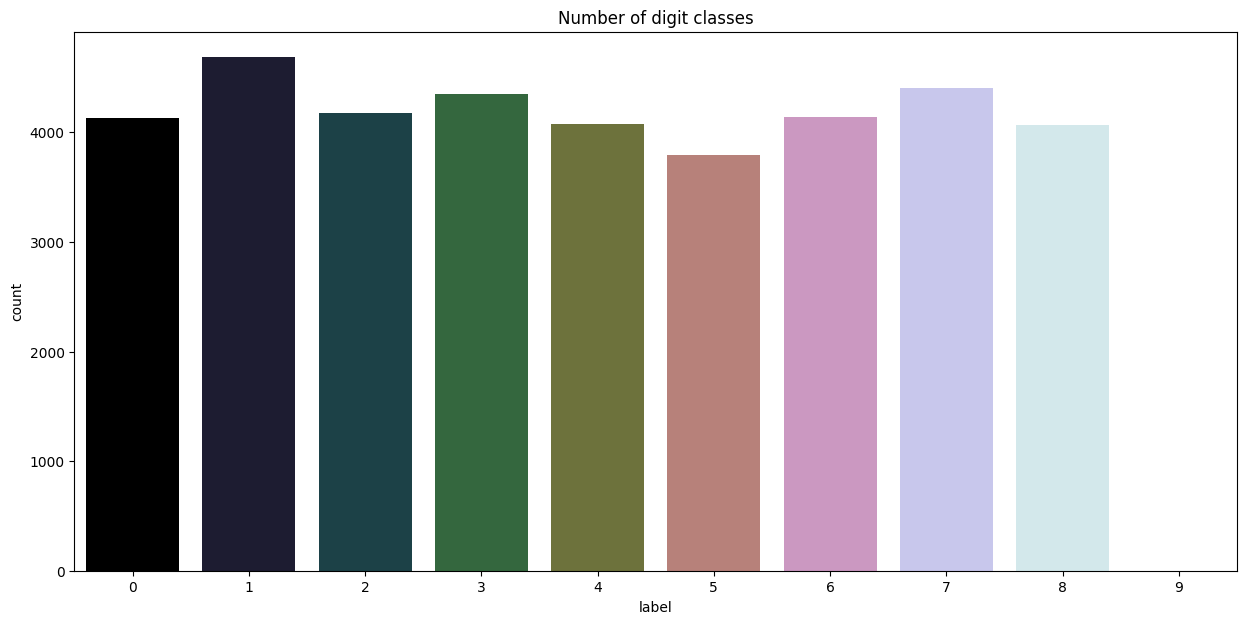

 	 # Train Data value counts # 
 label
1    4684
7    4401
3    4351
9    4188
2    4177
6    4137
0    4132
4    4072
8    4063
5    3795
Name: count, dtype: int64


In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 7))

g = sns.countplot(
    x=train_data["label"],
    hue=train_data["label"],
    palette="cubehelix",
    legend=False
)
plt.title("Number of digit classes")
plt.show()

print(" \t # Train Data value counts # \n", train_data["label"].value_counts())

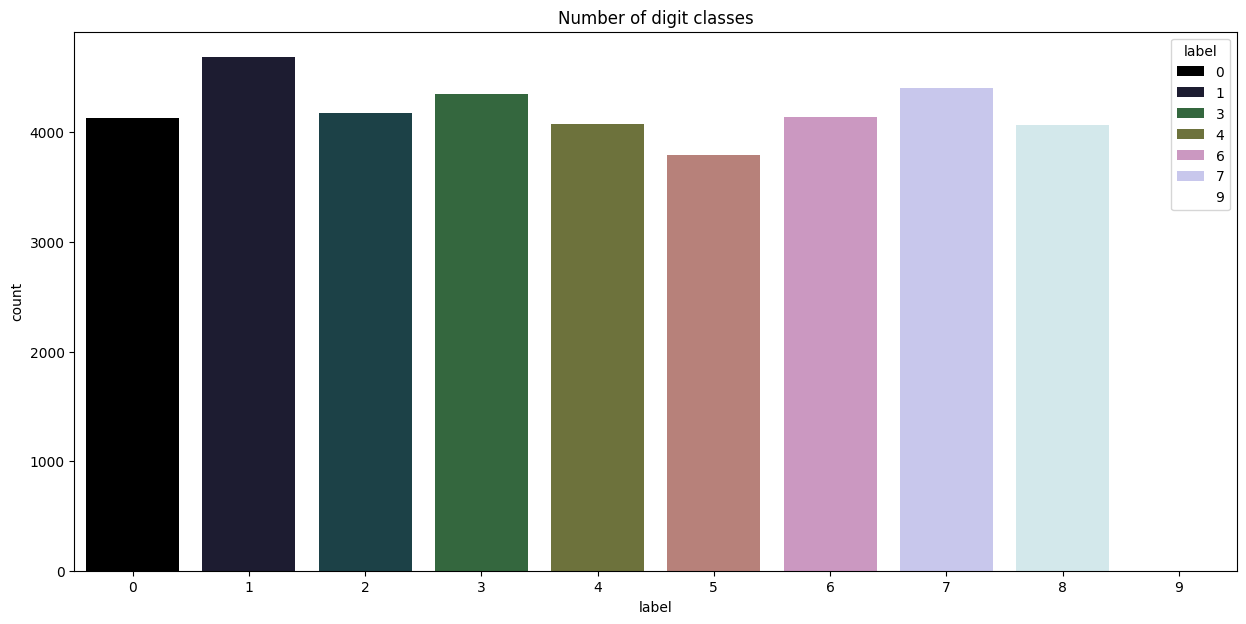

 	 # Train Data value counts # 
 label
1    4684
7    4401
3    4351
9    4188
2    4177
6    4137
0    4132
4    4072
8    4063
5    3795
Name: count, dtype: int64


In [88]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 7))

g = sns.countplot(
    x=train_data["label"],
    hue=train_data["label"],
    palette="cubehelix",
    legend=True
)
plt.title("Number of digit classes")
plt.show()

print(" \t # Train Data value counts # \n", train_data["label"].value_counts())

## Train -Test Split


In [89]:
X_train = train_data.drop(["label"], axis = 1).values
y_train = train_data.label.values

X_test = test_data.values

In [90]:
print("X_train shape --> ",X_train.shape)
print("y_train shape --> ",y_train.shape)
print("X_test shape --> ",X_test.shape)

X_train shape -->  (42000, 784)
y_train shape -->  (42000,)
X_test shape -->  (28000, 784)


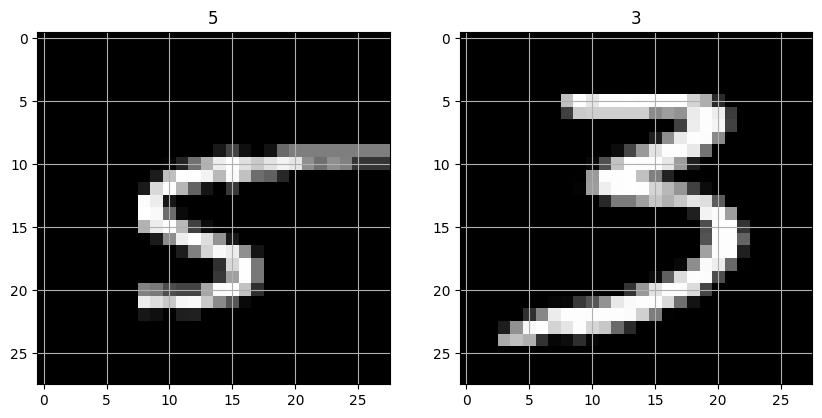

In [91]:
plt.figure(figsize=(10,8))
img = X_train[244]
img = img.reshape((28,28))
plt.subplot(1,2,1)
plt.imshow(img,cmap='gray')
plt.title(train_data.iloc[244,0])
plt.grid()

img1 = X_train[25]
img1 = img1.reshape((28,28))
plt.subplot(1,2,2)
plt.imshow(img1,cmap='gray')
plt.title(train_data.iloc[25,0])
plt.grid()
plt.show()

## Normalization ⁉️
Why do we want to normalize the pictures?

If we do not normalize, there may be errors due to certain colors. So, we first need to normalize.

Images are represented by values ​​between 0 and 255. Therefore

There are many ways to normalize. Here we prefer to subtract the average from the pixel value and divide by the average. In this way, we will bring all of our images to the [-1,1] range.




In [92]:
X_train = (X_train.astype(np.float32)-127.5)/127.5
print("X_train Shape --> ",X_train.shape)

X_train Shape -->  (42000, 784)


# Reshape ⁉️

Why do we need to reshape the pictures?

Because that's how keras works. For example, the input value for CNN is (28,28,1). Different models may require different input shapes.

Our input type for this model is (60000, 784).

Our data has already been prepared in this way, but I will show it in the comment lines in case it comes across in a different way./p>

In [93]:
X_train = X_train.reshape(-1, 28, 28)


In [94]:
X_train = X_train.reshape(X_train.shape[0], 28, 28)

Implementing with Keras ❔
Our In this section we will create our GANs model using keras.

Import Model Library 📗

Generator ❗

Create Generator

Generator Output

Generator Compile

Generator Summary

Discriminator ❗

Create Discriminator

Discriminator Output

Discriminator Compile

Discriminator Summary

GANs ❗❗

Create GANs

GANs Summary

Epochs and Batch Size ❓

Fit the Model ❓

Import Model Library
We will import the libraries we will use for our GANs model.

In [95]:
from keras.layers import Dense, Dropout, Input, ReLU
from keras.models import Sequential, Model
from keras.optimizers import Adam

I wanted to show the generator model that we will create above by visualizing it so that it can be better understood and fit in the head.

In this section, we will create our manufacturer model. While doing this, we will do it step by step for better understanding.

In [96]:
generator = Sequential()
generator.add(Dense(units = 512, input_dim = 100))
generator.add(ReLU())

generator.add(Dense(units = 512))
generator.add(ReLU())

generator.add(Dense(units = 1024))
generator.add(ReLU())

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


 We create our generator model. Below we will add an output layer to our model.




In [97]:
generator.add(Dense(units = 784, activation = "tanh")) ## Betweeen -1 and 1


Generator Compile

es, now we need to compile our model.

optimizer --> The optimizer does the process of updating our parameters for us here. some kind of healer I can say. There are methods used for multiple optimizers, and you should choose the most suitable one for the model.

loss --> It is a number that indicates how good or bad the model is to its prediction. As it approaches 0, the error starts to decrease.

In [98]:
generator.compile(loss = "binary_crossentropy",
                optimizer = Adam(learning_rate = 0.0001, beta_1 = 0.5))

In [99]:
generator.summary()


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_17 (Dense)                │ (None, 512)            │        51,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_12 (ReLU)                 │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_13 (ReLU)                 │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 1024)           │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_14 (ReLU)                 │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 784)            │       803,600 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,643,280 (6.27 MB)

 Trainable params: 1,643,280 (6.27 MB)

 Non-trainable params: 0 (0.00 B)

# Create Discriminator
n this section, we will create our discriminator layers.

In other words, we are creating the detective department that will distinguish whether it is real or fake for us.

In [100]:
discriminator = Sequential()
discriminator.add(Dense(units = 1024, input_dim = 784))
discriminator.add(ReLU())
discriminator.add(Dropout(0.4))

discriminator.add(Dense(units = 512))
discriminator.add(ReLU())
discriminator.add(Dropout(0.4))

discriminator.add(Dense(units = 256))
discriminator.add(ReLU())

In [101]:
discriminator.add(Dense(units = 1, activation = "sigmoid"))

In [102]:
discriminator.compile(loss = "binary_crossentropy",
                      optimizer = Adam(learning_rate = 0.0001, beta_1 = 0.5))

In [103]:
discriminator.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                │ (None, 1024)           │       803,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_15 (ReLU)                 │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_16 (ReLU)                 │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_17 (ReLU)                 │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,460,225 (5.57 MB)

 Trainable params: 1,460,225 (5.57 MB)

 Non-trainable params: 0 (0.00 B)

# Create GANs


We created our generator and discriminator models above.

Now we will combine these two to create your GANs model.

In [104]:
discriminator.trainable = False
gan_input = Input(shape = (100,))
x = generator(gan_input)
gan_output = discriminator(x)
gan = Model(inputs = gan_input, outputs = gan_output)
gan.compile(loss = "binary_crossentropy", optimizer = "adam")

In [105]:
gan.summary()


Model: "functional_48"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)      │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 784)            │     1,643,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_5 (Sequential)       │ (None, 1)              │     1,460,225 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,103,505 (11.84 MB)

 Trainable params: 1,643,280 (6.27 MB)

 Non-trainable params: 1,460,225 (5.57 MB)

In [106]:
epochs = 50
batch_size = 256

# Fit the model ❓


# In the picture above, I wanted to briefly summarize what we will do in this section.

Yes, it's time to train the gans model we've built so far.

For a better understanding of the training code. I will explain by writing comments on the code.

In [107]:
import numpy as np

steps_per_epoch = X_train.shape[0] // batch_size

for e in range(epochs):
    for step in range(steps_per_epoch):

        noise = np.random.normal(0, 1, [batch_size, 100])

        generated_images = generator(noise, training=False)

        idx = np.random.randint(low=0, high=X_train.shape[0], size=batch_size)
        image_batch = X_train[idx].reshape(batch_size, 784)

        x = np.concatenate([image_batch, generated_images])

        y_dis = np.zeros(batch_size * 2)
        y_dis[:batch_size] = 1.0

        discriminator.trainable = True
        discriminator.train_on_batch(x, y_dis)

        noise = np.random.normal(0, 1, [batch_size, 100])
        y_gen = np.ones(batch_size)

        discriminator.trainable = False
        gan.train_on_batch(noise, y_gen)

    print(f"Epoch {e + 1}/{epochs} Done")

Epoch 1/50 Done
Epoch 2/50 Done
Epoch 3/50 Done
Epoch 4/50 Done
Epoch 5/50 Done
Epoch 6/50 Done
Epoch 7/50 Done
Epoch 8/50 Done
Epoch 9/50 Done
Epoch 10/50 Done
Epoch 11/50 Done
Epoch 12/50 Done
Epoch 13/50 Done
Epoch 14/50 Done
Epoch 15/50 Done
Epoch 16/50 Done
Epoch 17/50 Done
Epoch 18/50 Done
Epoch 19/50 Done
Epoch 20/50 Done
Epoch 21/50 Done
Epoch 22/50 Done
Epoch 23/50 Done
Epoch 24/50 Done
Epoch 25/50 Done
Epoch 26/50 Done
Epoch 27/50 Done
Epoch 28/50 Done
Epoch 29/50 Done
Epoch 30/50 Done
Epoch 31/50 Done
Epoch 32/50 Done
Epoch 33/50 Done
Epoch 34/50 Done
Epoch 35/50 Done
Epoch 36/50 Done
Epoch 37/50 Done
Epoch 38/50 Done
Epoch 39/50 Done
Epoch 40/50 Done
Epoch 41/50 Done
Epoch 42/50 Done
Epoch 43/50 Done
Epoch 44/50 Done
Epoch 45/50 Done
Epoch 46/50 Done
Epoch 47/50 Done
Epoch 48/50 Done
Epoch 49/50 Done
Epoch 50/50 Done


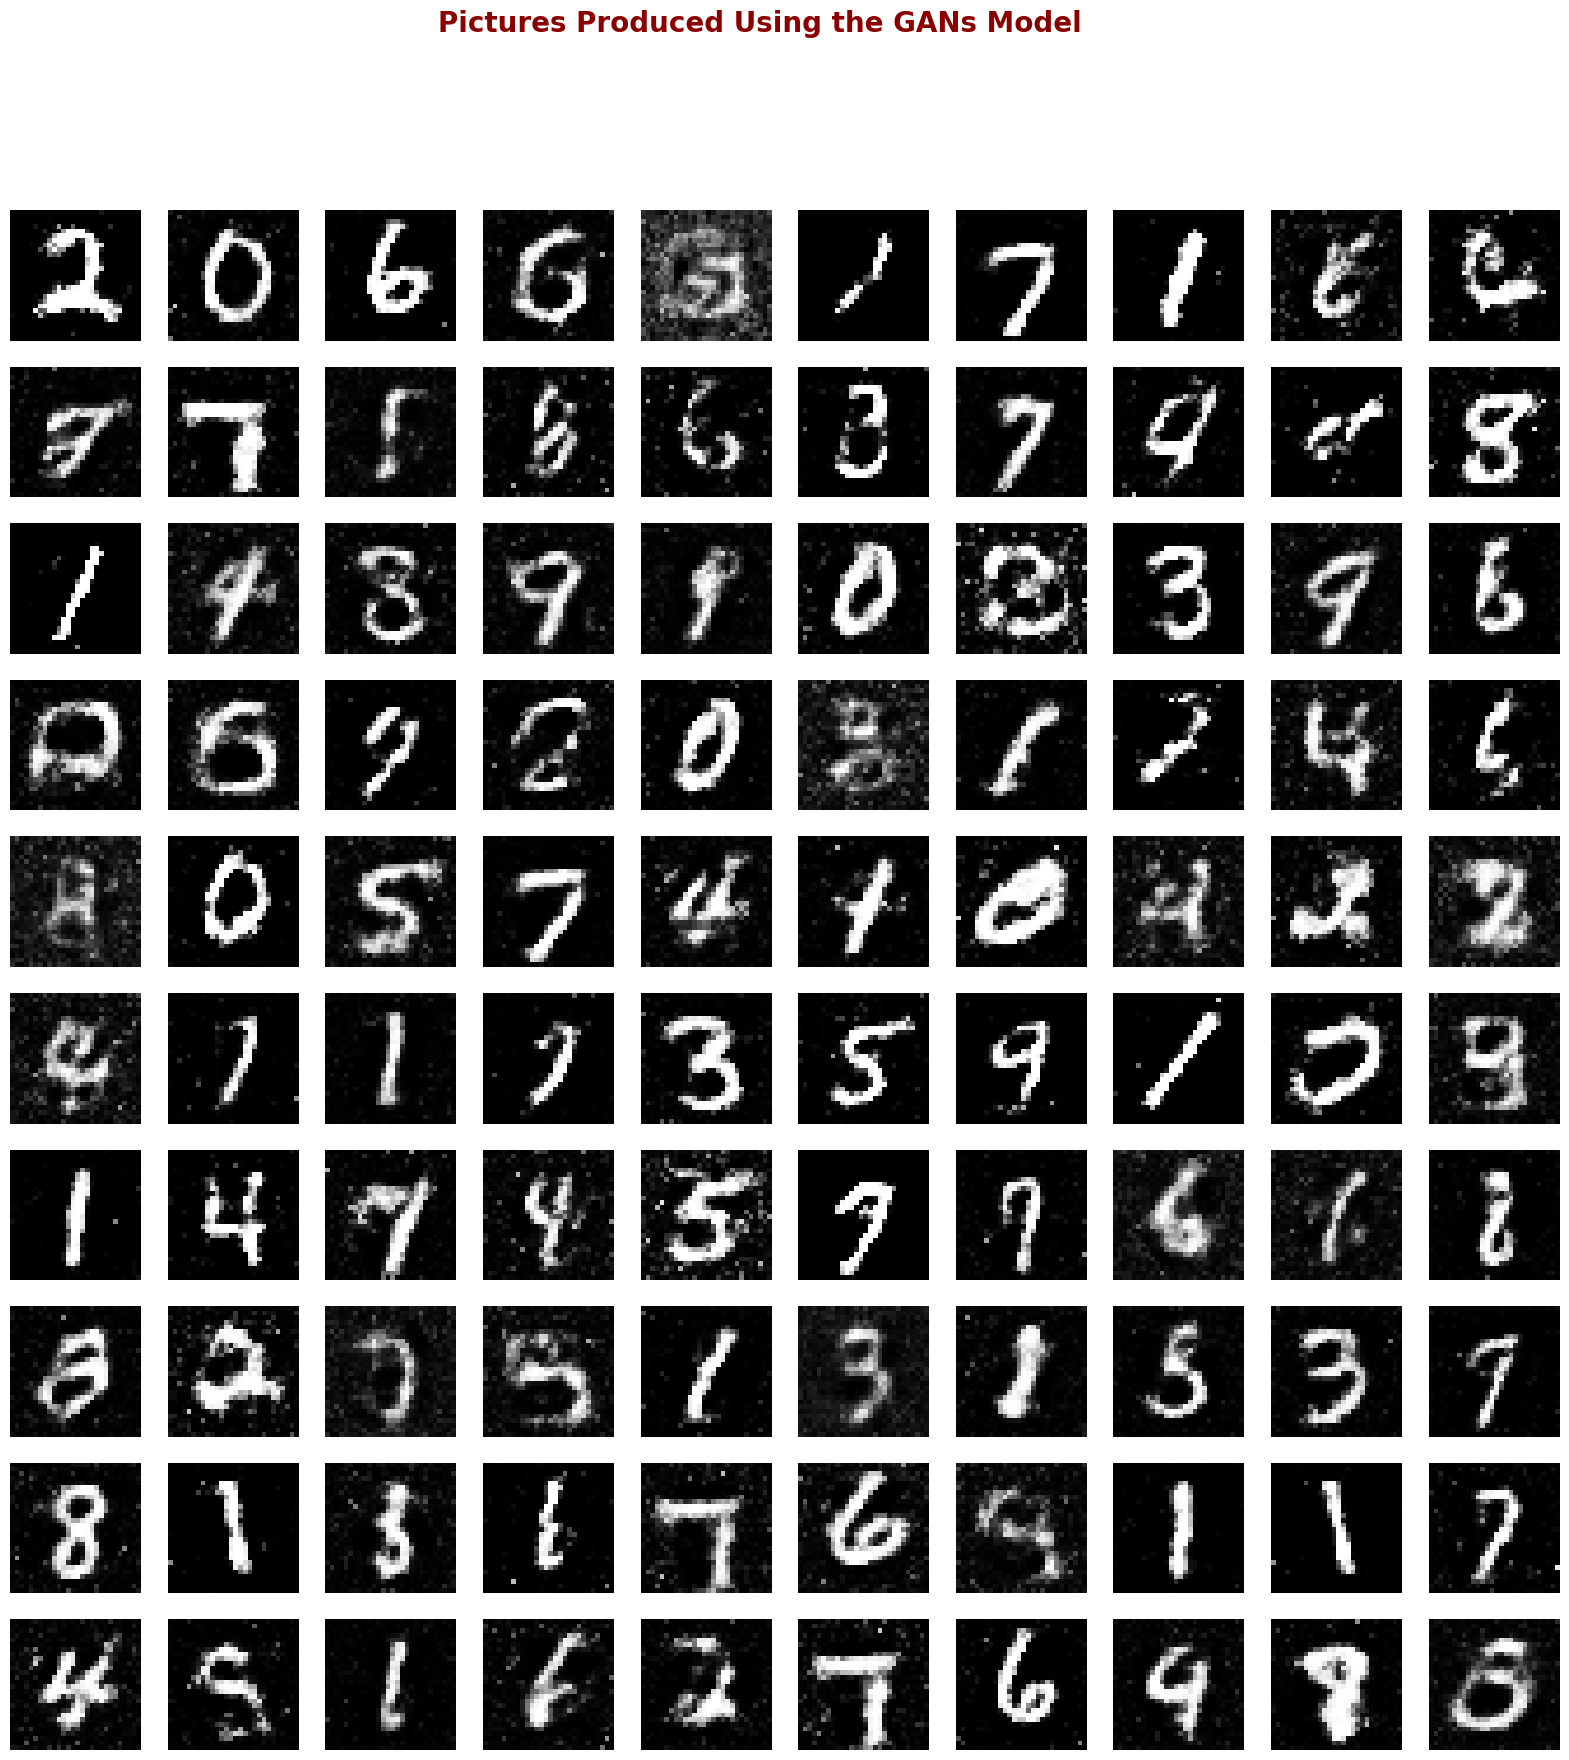

In [108]:
plt.figure(figsize=(20, 20))

noise = np.random.normal(loc=0, scale=1, size=[100, 100])
generated_images = generator(noise, training=False)
generated_images = np.array(generated_images).reshape(100, 28, 28)

for i in range(100):
    plt.subplot(10, 10, i + 1)
    plt.imshow(generated_images[i], interpolation='nearest', cmap="gray")
    plt.axis('off')

plt.suptitle("Pictures Produced Using the GANs Model", fontsize=20, color="darkred", fontweight='bold')
plt.show()

# Yes, we took a look at the images we created using the GANs model.

Even though it's a 50 epochs model, we produced pretty good pictures. There are pictures that are pretty close to the real thing.


CONCLUSION
Would be glad to hear your nice comments or questions.

You can check out other tutorials here.